In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Configuração visual
sns.set_theme(style="whitegrid")

In [8]:
def extract_hierarchy_nodes(labels):
  nodes = set()
  for label in labels:
    parts = label.split('.')
    for i in range(1, len(parts) + 1):
      nodes.add('.'.join(parts[:i]))
  return sorted(list(nodes))

def generate_hierarchical_bags(df, n_bags=200, bag_size=500, alpha=1.0):
  # CORREÇÃO 1: Reseta o índice internamente para evitar descompasso com loc/iloc.
  # Isso blinda a função caso o dataframe venha de um train_test_split ou filtro.
  df_internal = df.copy().reset_index(drop=True)
  
  base_classes = df_internal['label'].unique()
  all_nodes = extract_hierarchy_nodes(base_classes)
  
  base_prevalences = np.random.dirichlet(np.ones(len(base_classes)) * alpha, n_bags)
  bags_data = []
  
  for prev_vector in base_prevalences:
    bag_indices = []
    counts = np.round(prev_vector * bag_size).astype(int)
    
    diff = bag_size - counts.sum()
    if diff != 0:
      counts[np.argmax(counts)] += diff
        
    for cls, count in zip(base_classes, counts):
      if count > 0:
        cls_indices = df_internal[df_internal['label'] == cls].index
        
        # O replace=True garante que mesmo se 'count' for maior que a
        # quantidade real de instâncias da classe, não haverá erro.
        sampled = np.random.choice(cls_indices, size=count, replace=True)
        bag_indices.extend(sampled)
            
    hierarchical_prevs = {node: 0.0 for node in all_nodes}
    for cls, count in zip(base_classes, counts):
      parts = cls.split('.')
      for i in range(1, len(parts) + 1):
        node = '.'.join(parts[:i])
        hierarchical_prevs[node] += count / bag_size
            
    # CORREÇÃO 2: Usa .loc com os índices perfeitamente mapeados do df_internal
    bag_df = df_internal.loc[bag_indices].copy()
    
    # Opcional: embaralhar as linhas da bag para não ficarem agrupadas por classe
    bag_df = bag_df.sample(frac=1).reset_index(drop=True)
    
    bags_data.append({
      'bag_df': bag_df,
      'true_prevalences': hierarchical_prevs
    })
      
  return bags_data, all_nodes

In [13]:
df = pd.read_parquet('../data/multi-class/zooid/test.parquet')

# Gerando 500 bags com shift moderado/alto (alpha=0.5)
bags, all_nodes = generate_hierarchical_bags(df, n_bags=300, bag_size=100, alpha=1.)

In [17]:
bags[0]['bag_df']

,id,embeddings,label
0,578,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Cnidaria.Subphylum_Medusozoa.Class_Hydr...
1,496,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Arthropoda.Subphylum_Crustacea.Class_Ma...
2,555,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Arthropoda.Subphylum_Crustacea.Class_Ma...
3,116,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Mollusca.Class_Gastropoda.Superfamily_P...
4,135,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Mollusca.Class_Gastropoda.Superfamily_P...
...,...,...,...
95,101,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Mollusca.Class_Gastropoda.Superfamily_P...
96,119,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Mollusca.Class_Gastropoda.Superfamily_P...
97,501,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Arthropoda.Subphylum_Crustacea.Class_Ma...
98,595,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Cnidaria.Subphylum_Medusozoa.Class_Hydr...


In [19]:
bags[0]['true_prevalences']

{'Phylum_Annelida': np.float64(0.09),
 'Phylum_Annelida.Class_Polychaeta': np.float64(0.09),
 'Phylum_Arthropoda': np.float64(0.3),
 'Phylum_Arthropoda.Subphylum_Crustacea': np.float64(0.3),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Malacostraca': np.float64(0.13),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Malacostraca.Subclass_Eumalacostraca': np.float64(0.13),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Malacostraca.Subclass_Eumalacostraca.Superorder_Eucarida': np.float64(0.13),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Malacostraca.Subclass_Eumalacostraca.Superorder_Eucarida.Order_Decapoda': np.float64(0.02),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Malacostraca.Subclass_Eumalacostraca.Superorder_Eucarida.Order_Euphausiacea': np.float64(0.11),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Maxillopoda': np.float64(0.16),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Maxillopoda.Subclass_Cirripedia': np.float64(0.16),
 'Phylum_Arthropoda.Subphylum_Crustacea.Class_Os

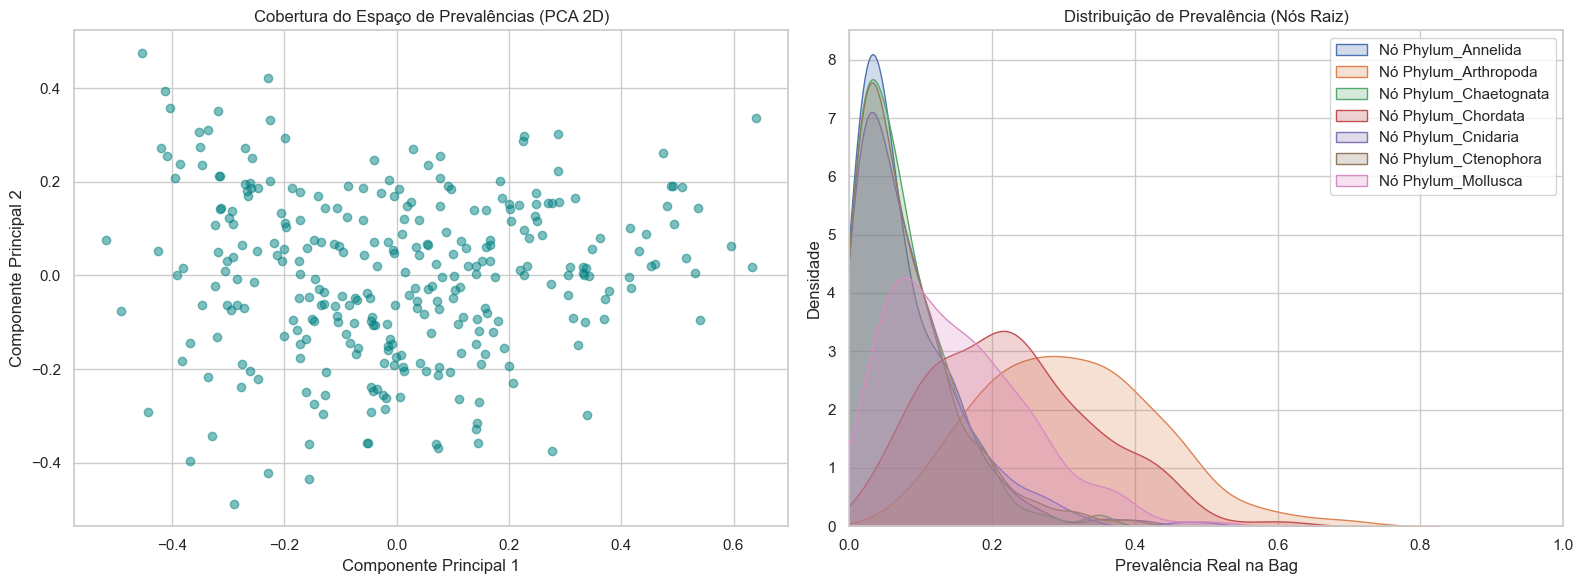

In [14]:
# Extraindo as prevalências de todas as bags para um DataFrame
prevs_list = [bag['true_prevalences'] for bag in bags]
df_prevs = pd.DataFrame(prevs_list)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Cobertura do Espaço (PCA)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_prevs)

axes[0].scatter(pca_result[:, 0], pca_result[:, 1], alpha=0.5, c='teal')
axes[0].set_title('Cobertura do Espaço de Prevalências (PCA 2D)')
axes[0].set_xlabel('Componente Principal 1')
axes[0].set_ylabel('Componente Principal 2')

# Gráfico 2: Distribuição de Prevalência para Nós de Nível Alto (Raízes)
# Selecionamos os nós de nível 1 (ex: 'A', 'G') para ver se variam bem de 0 a 1
root_nodes = [col for col in df_prevs.columns if '.' not in col]
for node in root_nodes:
    sns.kdeplot(df_prevs[node], ax=axes[1], label=f'Nó {node}', fill=True)

axes[1].set_title('Distribuição de Prevalência (Nós Raiz)')
axes[1].set_xlabel('Prevalência Real na Bag')
axes[1].set_ylabel('Densidade')
axes[1].set_xlim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()